In [ ]:
!pip install -q kaggle
!mkdir -p ~/.kaggle
!cp kaggle.json ~/.kaggle/
!chmod 600 ~/.kaggle/kaggle.json

!kaggle datasets download -d pranabr0y/celebdf-v2image-dataset --unzip

cp: cannot stat 'kaggle.json': No such file or directory
chmod: cannot access '/root/.kaggle/kaggle.json': No such file or directory
Dataset URL: https://www.kaggle.com/datasets/pranabr0y/celebdf-v2image-dataset
License(s): other
100% 1.46G/1.46G [00:20<00:00, 76.2MB/s]



In [ ]:
import os
import shutil
import random

print("--- MEMULAI PROSES BALANCING (UNDERSAMPLING) ---")

sumber_real = '/content/Celeb_V2/Train/real'
sumber_fake = '/content/Celeb_V2/Train/fake'

binary_dir = '/content/dataset_balanced/'
real_dir = os.path.join(binary_dir, 'Real')
fake_dir = os.path.join(binary_dir, 'Deepfake')

os.makedirs(real_dir, exist_ok=True)
os.makedirs(fake_dir, exist_ok=True)

list_real = os.listdir(sumber_real)
list_fake = os.listdir(sumber_fake)

jumlah_real = len(list_real)
jumlah_fake = len(list_fake)
print(f"Data Mentah -> Real: {jumlah_real}, Deepfake: {jumlah_fake}")

print(f"Target jumlah per kelas: {batas_maksimal} gambar.")

print("Menyalin data Real...")
for img in list_real:
    shutil.copy(os.path.join(sumber_real, img), os.path.join(real_dir, img))

random.seed(42)
fake_terpilih = random.sample(list_fake, batas_maksimal)

for img in fake_terpilih:
    shutil.copy(os.path.join(sumber_fake, img), os.path.join(fake_dir, img))

print(f"Total Real: {len(os.listdir(real_dir))}")
print(f"Total Deepfake: {len(os.listdir(fake_dir))}")

--- MEMULAI PROSES BALANCING (UNDERSAMPLING) ---
Data Mentah -> Real: 40288, Deepfake: 40536
Target jumlah per kelas: 40288 gambar.
Menyalin data Real...
Menyalin data Deepfake (Random Undersampling)...

✅ PENATAAN DATA SELESAI! DATA SUDAH SEIMBANG SEMPURNA 50:50.
Total Real: 40288
Total Deepfake: 40288


/tmp/ipykernel_1610/4249904738.py:21: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=kategori, y=sebelum_undersampling, ax=axes[0], palette=warna_bar)
/tmp/ipykernel_1610/4249904738.py:33: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=kategori, y=sesudah_undersampling, ax=axes[1], palette=warna_bar)


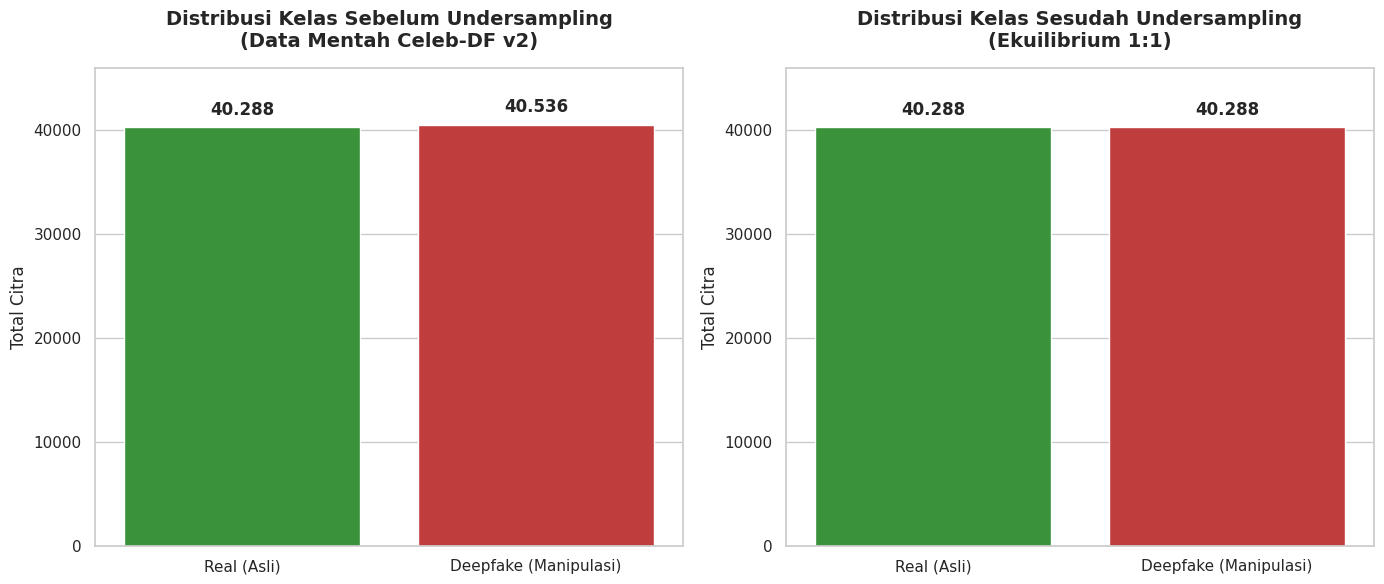

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")

kategori = ['Real (Asli)', 'Deepfake (Manipulasi)']
sebelum_undersampling = [40288, 40536]
sesudah_undersampling = [40288, 40288]

fig, axes = plt.subplots(1, 2, figsize=(14, 6))

warna_bar = ['#2ca02c', '#d62728']

sns.barplot(x=kategori, y=sebelum_undersampling, ax=axes[0], palette=warna_bar)
axes[0].set_title('Distribusi Kelas Sebelum Undersampling\n(Data Mentah Celeb-DF v2)', fontsize=14, fontweight='bold', pad=15)
axes[0].set_ylabel('Total Citra', fontsize=12)
axes[0].set_ylim(0, 46000)

for i, v in enumerate(sebelum_undersampling):
    axes[0].text(i, v + 800, f"{v:,}".replace(',', '.'), ha='center', va='bottom', fontsize=12, fontweight='bold')

sns.barplot(x=kategori, y=sesudah_undersampling, ax=axes[1], palette=warna_bar)
axes[1].set_title('Distribusi Kelas Sesudah Undersampling\n(Ekuilibrium 1:1)', fontsize=14, fontweight='bold', pad=15)
axes[1].set_ylabel('Total Citra', fontsize=12)
axes[1].set_ylim(0, 46000)

for i, v in enumerate(sesudah_undersampling):
    axes[1].text(i, v + 800, f"{v:,}".replace(',', '.'), ha='center', va='bottom', fontsize=12, fontweight='bold')

plt.tight_layout()
plt.show()

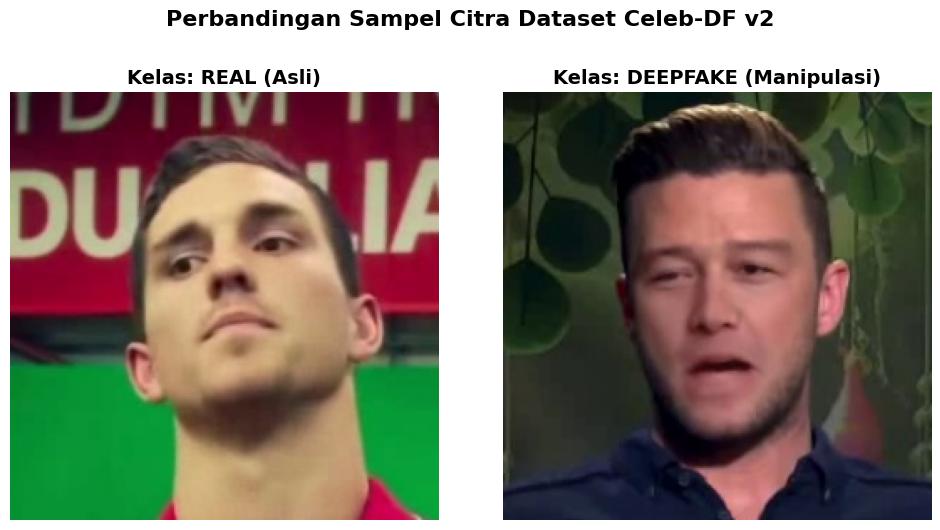

In [ ]:
real_dir = '/content/dataset_balanced/Real'
fake_dir = '/content/dataset_balanced/Deepfake'

nama_file_real = os.listdir(real_dir)[0]
nama_file_fake = os.listdir(fake_dir)[0]

path_sample_real = os.path.join(real_dir, nama_file_real)
path_sample_fake = os.path.join(fake_dir, nama_file_fake)

img_real = cv2.cvtColor(cv2.imread(path_sample_real), cv2.COLOR_BGR2RGB)
img_fake = cv2.cvtColor(cv2.imread(path_sample_fake), cv2.COLOR_BGR2RGB)

fig, axes = plt.subplots(1, 2, figsize=(10, 5))
axes[0].imshow(img_real)
axes[0].set_title("Kelas: REAL (Asli)", fontsize=14, fontweight='bold')
axes[0].axis('off')

axes[1].imshow(img_fake)
axes[1].set_title("Kelas: DEEPFAKE (Manipulasi)", fontsize=14, fontweight='bold')
axes[1].axis('off')

plt.suptitle("Perbandingan Sampel Citra Dataset Celeb-DF v2", fontsize=16, fontweight='bold', y=1.05)
plt.tight_layout()
plt.show()

In [ ]:
import numpy as np
import tensorflow as tf
from tensorflow.keras import layers, models, optimizers
from tensorflow.keras.applications import MobileNetV2, ResNet50
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from tensorflow.keras.callbacks import EarlyStopping
from sklearn.metrics import classification_report

def random_jpeg_compression(image):
    img_uint8 = image.astype(np.uint8)
    if random.random() < 0.5:
        quality = random.randint(30, 90)
        encode_param = [int(cv2.IMWRITE_JPEG_QUALITY), quality]
        result, encimg = cv2.imencode('.jpg', img_uint8, encode_param)
        decimg = cv2.imdecode(encimg, 1)
        return decimg.astype(np.float32)
    return img_uint8.astype(np.float32)

IMG_SIZE = (224, 224)
BATCH_SIZE = 32

datagen_train = ImageDataGenerator(
    rescale=1./255,
    preprocessing_function=random_jpeg_compression,
    validation_split=0.2
)

datagen_val = ImageDataGenerator(
    rescale=1./255,
    validation_split=0.2
)

print("Memuat Data Training...")
train_generator = datagen_train.flow_from_directory(
    binary_dir,
    target_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    class_mode='categorical',
    subset='training',
    shuffle=True,
    seed=42
)

print("\nMemuat Data Validation...")
val_generator = datagen_val.flow_from_directory(
    binary_dir,
    target_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    class_mode='categorical',
    subset='validation',
    shuffle=False,
    seed=42
)

Memuat Data Training...
Found 64462 images belonging to 2 classes.

Memuat Data Validation...
Found 16114 images belonging to 2 classes.


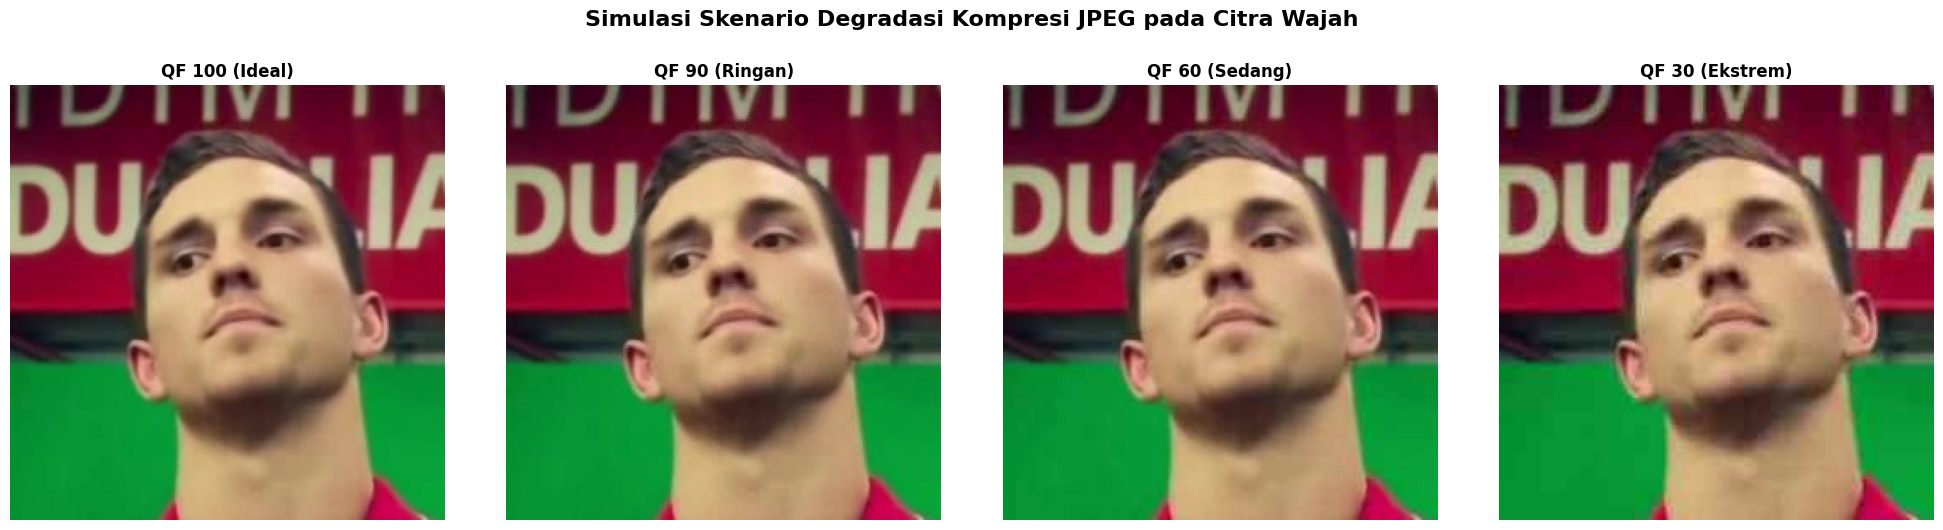

In [ ]:
def compress_image(image_path, quality):
    img = cv2.imread(image_path)
    encode_param = [int(cv2.IMWRITE_JPEG_QUALITY), quality]
    result, encimg = cv2.imencode('.jpg', img, encode_param)
    decimg = cv2.imdecode(encimg, 1)
    return cv2.cvtColor(decimg, cv2.COLOR_BGR2RGB)

img_qf100 = compress_image(path_sample_real, 100)
img_qf90 = compress_image(path_sample_real, 90)
img_qf60 = compress_image(path_sample_real, 60)
img_qf30 = compress_image(path_sample_real, 30)

fig2, axes2 = plt.subplots(1, 4, figsize=(20, 5))

axes2[0].imshow(img_qf100)
axes2[0].set_title("QF 100 (Ideal)", fontsize=12, fontweight='bold')
axes2[0].axis('off')

axes2[1].imshow(img_qf90)
axes2[1].set_title("QF 90 (Ringan)", fontsize=12, fontweight='bold')
axes2[1].axis('off')

axes2[2].imshow(img_qf60)
axes2[2].set_title("QF 60 (Sedang)", fontsize=12, fontweight='bold')
axes2[2].axis('off')

axes2[3].imshow(img_qf30)
axes2[3].set_title("QF 30 (Ekstrem)", fontsize=12, fontweight='bold')
axes2[3].axis('off')

plt.suptitle("Simulasi Skenario Degradasi Kompresi JPEG pada Citra Wajah", fontsize=16, fontweight='bold', y=1.05)
plt.tight_layout()
plt.show()

In [ ]:
early_stop = EarlyStopping(
    monitor='val_loss',
    patience=10,
    restore_best_weights=True,
    verbose=1
)

EPOCHS = 50
print("✅ Rem otomatis (Early Stopping) siap!")

✅ Rem otomatis (Early Stopping) siap!


In [ ]:
print("--- MEMBANGUN MOBILENETV2 ---")
base_mobile = MobileNetV2(weights='imagenet', include_top=False, input_shape=(224, 224, 3))
base_mobile.trainable = True

for layer in base_mobile.layers[:100]:
    layer.trainable = False

model_mobile = models.Sequential([
    base_mobile,
    layers.GlobalAveragePooling2D(),
    layers.Dense(128, activation='relu'),
    layers.Dropout(0.5),
    layers.Dense(2, activation='softmax')
])

model_mobile.compile(
    optimizer=optimizers.Adam(learning_rate=1e-5),
    loss='categorical_crossentropy',
    metrics=['accuracy']
)

print("--- TRAINING MOBILENETV2 DIMULAI ---")
history_mobile = model_mobile.fit(
    train_generator,
    validation_data=val_generator,
    epochs=EPOCHS,
    callbacks=[early_stop]
)

model_mobile.save('mobilenetv2_celebdf.keras')
print("✅ MobileNetV2 tersimpan!")

--- MEMBANGUN MOBILENETV2 ---
9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 1s 0us/step
--- TRAINING MOBILENETV2 DIMULAI ---
Epoch 1/50
2015/2015 ━━━━━━━━━━━━━━━━━━━━ 252s 104ms/step - accuracy: 0.6973 - loss: 0.5765 - val_accuracy: 0.6994 - val_loss: 0.7110
Epoch 2/50
2015/2015 ━━━━━━━━━━━━━━━━━━━━ 165s 82ms/step - accuracy: 0.8463 - loss: 0.3464 - val_accuracy: 0.8210 - val_loss: 0.4514
Epoch 3/50
2015/2015 ━━━━━━━━━━━━━━━━━━━━ 177s 88ms/step - accuracy: 0.8983 - loss: 0.2460 - val_accuracy: 0.8311 - val_loss: 0.4274
Epoch 4/50
2015/2015 ━━━━━━━━━━━━━━━━━━━━ 164s 82ms/step - accuracy: 0.9238 - loss: 0.1888 - val_accuracy: 0.8368 - val_loss: 0.4481
Epoch 5/50
2015/2015 ━━━━━━━━━━━━━━━━━━━━ 180s 90ms/step - accuracy: 0.9386 - loss: 0.1553 - val_accuracy: 0.8194 - val_loss: 0.5049
Epoch 6/50
2015/2015 ━━━━━━━━━━━━━━━━━━━━ 166s 82ms/step - accuracy: 0.9504 - loss: 0.1262 - val_accuracy: 0.8182 - val_loss: 0.5567
Epoch 7/50
2015/2015 ━━━━━━━━━━━━━━━━━━━━ 174s 86ms/step - accuracy: 0.9597 - loss: 0

In [ ]:
print("--- MEMBANGUN RESNET50 ---")
base_resnet = ResNet50(weights='imagenet', include_top=False, input_shape=(224, 224, 3))
base_resnet.trainable = True

for layer in base_resnet.layers[:143]:
    layer.trainable = False

model_resnet = models.Sequential([
    base_resnet,
    layers.GlobalAveragePooling2D(),
    layers.Dense(128, activation='relu'),
    layers.Dropout(0.5),
    layers.Dense(2, activation='softmax')
])

model_resnet.compile(
    optimizer=optimizers.Adam(learning_rate=1e-5),
    loss='categorical_crossentropy',
    metrics=['accuracy']
)

print("--- TRAINING RESNET50 DIMULAI ---")
history_resnet = model_resnet.fit(
    train_generator,
    validation_data=val_generator,
    epochs=EPOCHS,
    callbacks=[early_stop]
)

model_resnet.save('resnet50_celebdf.keras')
print("✅ ResNet50 tersimpan!")

--- MEMBANGUN RESNET50 ---
94765736/94765736 ━━━━━━━━━━━━━━━━━━━━ 3s 0us/step
--- TRAINING RESNET50 DIMULAI ---
Epoch 1/50
2015/2015 ━━━━━━━━━━━━━━━━━━━━ 342s 158ms/step - accuracy: 0.6882 - loss: 0.5804 - val_accuracy: 0.6996 - val_loss: 0.5697
Epoch 2/50
2015/2015 ━━━━━━━━━━━━━━━━━━━━ 297s 148ms/step - accuracy: 0.7362 - loss: 0.5176 - val_accuracy: 0.5542 - val_loss: 0.9679
Epoch 3/50
2015/2015 ━━━━━━━━━━━━━━━━━━━━ 298s 148ms/step - accuracy: 0.7547 - loss: 0.4890 - val_accuracy: 0.6861 - val_loss: 1.0602
Epoch 4/50
2015/2015 ━━━━━━━━━━━━━━━━━━━━ 299s 148ms/step - accuracy: 0.7673 - loss: 0.4676 - val_accuracy: 0.7126 - val_loss: 0.6119
Epoch 5/50
2015/2015 ━━━━━━━━━━━━━━━━━━━━ 299s 148ms/step - accuracy: 0.7782 - loss: 0.4510 - val_accuracy: 0.5374 - val_loss: 1.6609
Epoch 6/50
2015/2015 ━━━━━━━━━━━━━━━━━━━━ 298s 148ms/step - accuracy: 0.7872 - loss: 0.4375 - val_accuracy: 0.7207 - val_loss: 0.6816
Epoch 7/50
2015/2015 ━━━━━━━━━━━━━━━━━━━━ 299s 148ms/step - accuracy: 0.7973 - loss:

MENCETAK GRAFIK MOBILENETV2...


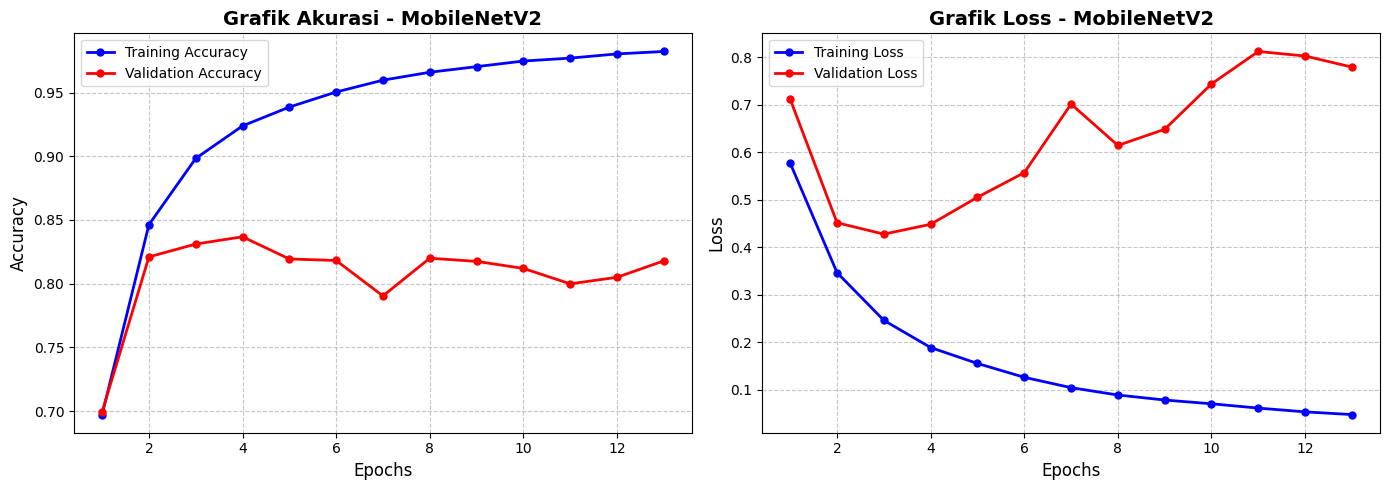


MENCETAK GRAFIK RESNET50...


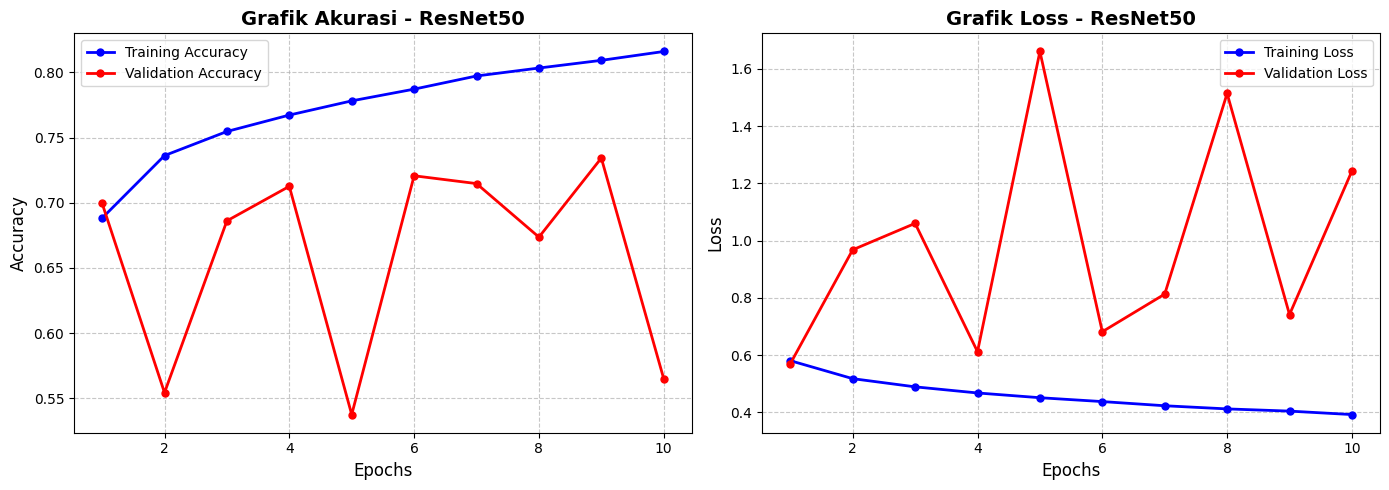

In [ ]:
import matplotlib.pyplot as plt

# --- DATA LOG MOBILENETV2 ---
mobile_acc = [0.6973, 0.8463, 0.8983, 0.9238, 0.9386, 0.9504, 0.9597, 0.9659, 0.9703, 0.9747, 0.9770, 0.9803, 0.9822]
mobile_loss = [0.5765, 0.3464, 0.2460, 0.1888, 0.1553, 0.1262, 0.1044, 0.0889, 0.0784, 0.0705, 0.0614, 0.0535, 0.0478]
mobile_val_acc = [0.6994, 0.8210, 0.8311, 0.8368, 0.8194, 0.8182, 0.7904, 0.8200, 0.8175, 0.8120, 0.7999, 0.8050, 0.8179]
mobile_val_loss = [0.7110, 0.4514, 0.4274, 0.4481, 0.5049, 0.5567, 0.7010, 0.6140, 0.6479, 0.7434, 0.8116, 0.8021, 0.7788]
mobile_epochs = range(1, len(mobile_acc) + 1)

# --- DATA LOG RESNET50 ---
resnet_acc = [0.6882, 0.7362, 0.7547, 0.7673, 0.7782, 0.7872, 0.7973, 0.8034, 0.8093, 0.8161]
resnet_loss = [0.5804, 0.5176, 0.4890, 0.4676, 0.4510, 0.4375, 0.4229, 0.4119, 0.4042, 0.3921]
resnet_val_acc = [0.6996, 0.5542, 0.6861, 0.7126, 0.5374, 0.7207, 0.7147, 0.6736, 0.7343, 0.5649]
resnet_val_loss = [0.5697, 0.9679, 1.0602, 0.6119, 1.6609, 0.6816, 0.8131, 1.5141, 0.7416, 1.2433]
resnet_epochs = range(1, len(resnet_acc) + 1)

def plot_rekonstruksi(epochs, acc, loss, val_acc, val_loss, nama_model):
    plt.figure(figsize=(14, 5))

    # Grafik Akurasi
    plt.subplot(1, 2, 1)
    plt.plot(epochs, acc, 'b-o', label='Training Accuracy', linewidth=2, markersize=5)
    plt.plot(epochs, val_acc, 'r-o', label='Validation Accuracy', linewidth=2, markersize=5)
    plt.title(f'Grafik Akurasi - {nama_model}', fontsize=14, fontweight='bold')
    plt.xlabel('Epochs', fontsize=12)
    plt.ylabel('Accuracy', fontsize=12)
    plt.legend()
    plt.grid(True, linestyle='--', alpha=0.7)

    # Grafik Loss
    plt.subplot(1, 2, 2)
    plt.plot(epochs, loss, 'b-o', label='Training Loss', linewidth=2, markersize=5)
    plt.plot(epochs, val_loss, 'r-o', label='Validation Loss', linewidth=2, markersize=5)
    plt.title(f'Grafik Loss - {nama_model}', fontsize=14, fontweight='bold')
    plt.xlabel('Epochs', fontsize=12)
    plt.ylabel('Loss', fontsize=12)
    plt.legend()
    plt.grid(True, linestyle='--', alpha=0.7)

    plt.tight_layout()
    plt.show()

# Mencetak Grafik
print("MENCETAK GRAFIK MOBILENETV2...")
plot_rekonstruksi(mobile_epochs, mobile_acc, mobile_loss, mobile_val_acc, mobile_val_loss, "MobileNetV2")

print("\nMENCETAK GRAFIK RESNET50...")
plot_rekonstruksi(resnet_epochs, resnet_acc, resnet_loss, resnet_val_acc, resnet_val_loss, "ResNet50")

In [ ]:
def evaluasi_otomatis(nama_model_str, model, qf_value, direktori_data):
    print(f"\n{'='*40}")
    print(f"MODEL: {nama_model_str} | QUALITY FACTOR: {qf_value}")
    print(f"{'='*40}")

    def apply_fixed_qf(image):
        if qf_value == 100:
            return image
        img_uint8 = image.astype(np.uint8)
        encode_param = [int(cv2.IMWRITE_JPEG_QUALITY), qf_value]
        result, encimg = cv2.imencode('.jpg', img_uint8, encode_param)
        decimg = cv2.imdecode(encimg, 1)
        return decimg.astype(np.float32)

    test_datagen = ImageDataGenerator(
        rescale=1./255,
        preprocessing_function=apply_fixed_qf,
        validation_split=0.2
    )

    test_generator = test_datagen.flow_from_directory(
        direktori_data,
        target_size=(224, 224),
        batch_size=32,
        class_mode='categorical',
        subset='validation',
        shuffle=False,
        seed=42
    )

    predictions = model.predict(test_generator, verbose=0)
    y_pred = np.argmax(predictions, axis=1)
    y_true = test_generator.classes

    print(classification_report(y_true, y_pred, target_names=list(test_generator.class_indices.keys())))

In [ ]:
evaluasi_otomatis("MobileNetV2", model_mobile, 100, binary_dir)
evaluasi_otomatis("MobileNetV2", model_mobile, 90, binary_dir)
evaluasi_otomatis("MobileNetV2", model_mobile, 60, binary_dir)
evaluasi_otomatis("MobileNetV2", model_mobile, 30, binary_dir)

evaluasi_otomatis("ResNet50", model_resnet, 100, binary_dir)
evaluasi_otomatis("ResNet50", model_resnet, 90, binary_dir)
evaluasi_otomatis("ResNet50", model_resnet, 60, binary_dir)
evaluasi_otomatis("ResNet50", model_resnet, 30, binary_dir)


MODEL: MobileNetV2 | QUALITY FACTOR: 100
Found 16114 images belonging to 2 classes.
              precision    recall  f1-score   support

    Deepfake       0.82      0.85      0.83      8057
        Real       0.84      0.81      0.83      8057

    accuracy                           0.83     16114
   macro avg       0.83      0.83      0.83     16114
weighted avg       0.83      0.83      0.83     16114


MODEL: MobileNetV2 | QUALITY FACTOR: 90
Found 16114 images belonging to 2 classes.
              precision    recall  f1-score   support

    Deepfake       0.82      0.85      0.83      8057
        Real       0.84      0.81      0.82      8057

    accuracy                           0.83     16114
   macro avg       0.83      0.83      0.83     16114
weighted avg       0.83      0.83      0.83     16114


MODEL: MobileNetV2 | QUALITY FACTOR: 60
Found 16114 images belonging to 2 classes.
              precision    recall  f1-score   support

    Deepfake       0.81      0.83     